# FIGURES_Regenerate: thesis data charts from the locked final run

Redraws every **data-bearing** thesis figure from the locked outputs, so each chart is traceable to code:
Figures 3.6, 3.7 and 3.8 (TweetEval EDA) and 5.1–5.6 (results). Diagrams (process figures) contain no measured data and are not redrawn.

Inputs (read-only): `LJMU_FINAL_EXPERIMENT_RUN/data/tweeteval_*_final.parquet` and `results/*.csv` written by the locked notebooks.
Output: PNGs (300 dpi, 6.1 in wide) plus `FIGURE_VALUES.csv` listing every plotted number, in `figures/thesis_regenerated/`.

In [1]:
from google.colab import drive; drive.mount('/content/drive')
!pip -q install emoji
import os, re, glob, json, numpy as np, pandas as pd, matplotlib.pyplot as plt, emoji
from pathlib import Path
ROOT = Path('/content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN')
RES, DATA = ROOT/'results', ROOT/'data'
OUT = ROOT/'figures'/'thesis_regenerated'; OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Liberation Serif', 'Times New Roman', 'DejaVu Serif'], 'font.size': 11})
C = {'neg': '#A8475A', 'neu': '#8C9AA7', 'pos': '#2E8582', 'navy': '#1F3A5F', 'orange': '#D4952B'}
VALUES = []
def log(fig, item, value): VALUES.append({'figure': fig, 'item': item, 'value': value})
def save(fig, name):
    for s in ('top', 'right'):
        for ax in fig.axes: ax.spines[s].set_visible(False)
    fig.tight_layout(); fig.savefig(OUT/name, dpi=300); plt.show(); print('saved', OUT/name)
def need(path):
    assert path.exists(), f'missing {path}'; return path

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 14.4 MB/s eta 0:00:00


## Chapter 3: TweetEval EDA (Figures 3.6–3.8)

train 45615
validation 2000
test 12284


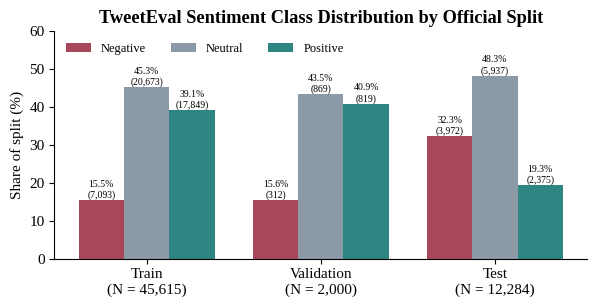

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig3_6_class_distribution.png


In [2]:
splits = {s: pd.read_parquet(need(DATA/f'tweeteval_{s}_final.parquet')) for s in ('train', 'validation', 'test')}
for s, d in splits.items(): print(s, len(d))
lab = {0: 'Negative', 1: 'Neutral', 2: 'Positive'}
# Figure 3.6 class distribution
fig, ax = plt.subplots(figsize=(6.1, 3.2)); w = 0.26
for i, (k, col) in enumerate(zip((0, 1, 2), (C['neg'], C['neu'], C['pos']))):
    sh = [100 * (d.label_id == k).mean() for d in splits.values()]
    n = [int((d.label_id == k).sum()) for d in splits.values()]
    bars = ax.bar(np.arange(3) + (i - 1) * w, sh, w, color=col, label=lab[k])
    for b, v, c_ in zip(bars, sh, n):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.6, f'{v:.1f}%\n({c_:,})', ha='center', fontsize=7)
    for s, v, c_ in zip(splits, sh, n): log('3.6', f'{s} {lab[k]}', f'{c_} ({v:.2f}%)')
ax.set_xticks(range(3)); ax.set_xticklabels([f'{s.title()}\n(N = {len(d):,})' for s, d in splits.items()])
ax.set_ylabel('Share of split (%)'); ax.set_ylim(0, 60); ax.legend(ncol=3, frameon=False, fontsize=9)
ax.set_title('TweetEval Sentiment Class Distribution by Official Split', fontweight='bold'); save(fig, 'Fig3_6_class_distribution.png')

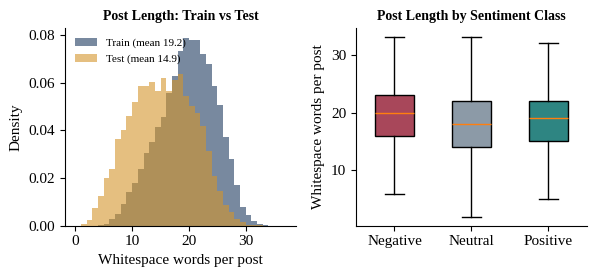

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig3_7_post_length.png


In [3]:
# Figure 3.7 post length: left train vs test; right by class, all splits pooled
wc = {s: d.text.astype(str).str.split().str.len() for s, d in splits.items()}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(6.1, 2.9))
bins = np.arange(0, 38)
for s, col in (('train', C['navy']), ('test', C['orange'])):
    a1.hist(wc[s], bins=bins, density=True, alpha=0.6, color=col, label=f'{s.title()} (mean {wc[s].mean():.1f})')
    log('3.7', f'mean words {s}', round(wc[s].mean(), 2))
a1.legend(frameon=False, fontsize=8, loc='upper left'); a1.set_xlabel('Whitespace words per post'); a1.set_ylabel('Density')
a1.set_title('Post Length: Train vs Test', fontweight='bold', fontsize=10)
allp = pd.concat(splits.values()); allw = allp.text.astype(str).str.split().str.len()
data = [allw[allp.label_id == k] for k in (0, 1, 2)]
bp = a2.boxplot(data, patch_artist=True, showfliers=False, widths=0.5)
for p_, col in zip(bp['boxes'], (C['neg'], C['neu'], C['pos'])): p_.set_facecolor(col)
for k, d_ in zip((0, 1, 2), data): log('3.7', f'pooled {lab[k]} Q1/med/Q3', np.percentile(d_, [25, 50, 75]).tolist())
a2.set_xticklabels([lab[k] for k in (0, 1, 2)]); a2.set_ylabel('Whitespace words per post')
a2.set_title('Post Length by Sentiment Class', fontweight='bold', fontsize=10); save(fig, 'Fig3_7_post_length.png')

train | slang column: slang_count | sarcasm column: sarcasm_indicator
validation | slang column: slang_count | sarcasm column: sarcasm_indicator
test | slang column: slang_count | sarcasm column: sarcasm_indicator


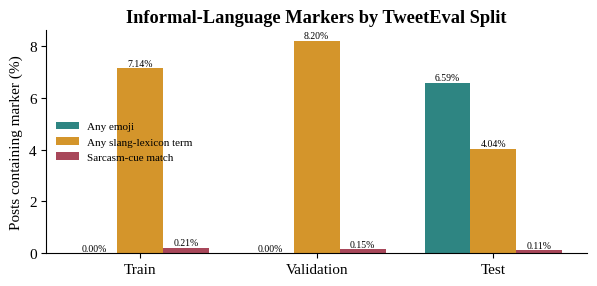

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig3_8_markers.png


In [4]:
# Figure 3.8 informal-language markers. Uses the frozen tagger's own counts where it exposes them.
import sys; sys.path.insert(0, '/content')
try:
    import final_thesis_utils as ftu
except ImportError:
    ftu = None
if ftu is None:
    try:
        import io, google.auth
        from google.colab import auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaIoBaseDownload
        auth.authenticate_user(); creds, _ = google.auth.default()
        req = build('drive', 'v3', credentials=creds, cache_discovery=False).files().get_media(fileId='14KfwtUf2zSd_jlW7i-6K8XgBJ62Aqk02')
        with io.FileIO('/content/final_thesis_utils.py', 'wb') as fh:
            dl = MediaIoBaseDownload(fh, req); done = False
            while not done: _, done = dl.next_chunk()
        import final_thesis_utils as ftu
    except Exception as ex:
        print('could not load final_thesis_utils:', ex)
if ftu is None:
    print('final_thesis_utils not available: slang/sarcasm will use fallbacks (values may differ slightly)')
rows = {}
for s, d in splits.items():
    t = ftu.tag_subgroups(d.copy(), 'text') if ftu is not None else d.copy()
    emo = d.text.astype(str).map(lambda x: emoji.emoji_count(x) > 0)
    scol = next((c for c in t.columns if 'slang' in c.lower() and 'count' in c.lower()), None)
    sarc = next((c for c in t.columns if 'sarcas' in c.lower() and c != 'subgroup'), None)
    if scol: sl = t[scol] > 0
    else:
        lex = {w.lower() for w in getattr(ftu, 'SLANG_TERMS', [])}
        sl = d.text.astype(str).str.lower().str.findall(r"[a-z0-9']+").map(lambda ws: any(w in lex for w in ws)); print('slang fallback tokeniser used')
    sa = t[sarc].astype(bool) if sarc else pd.Series(False, index=d.index)
    print(s, '| slang column:', scol, '| sarcasm column:', sarc)
    rows[s] = [100 * emo.mean(), 100 * sl.mean(), 100 * sa.mean()]
    for name, v in zip(('emoji', 'slang', 'sarcasm'), rows[s]): log('3.8', f'{s} {name} %', round(v, 2))
fig, ax = plt.subplots(figsize=(6.1, 3.0)); w = 0.26
for i, (name, col) in enumerate(zip(('Any emoji', 'Any slang-lexicon term', 'Sarcasm-cue match'), (C['pos'], C['orange'], C['neg']))):
    v = [rows[s][i] for s in splits]; bars = ax.bar(np.arange(3) + (i - 1) * w, v, w, color=col, label=name)
    for b, x in zip(bars, v): ax.text(b.get_x() + b.get_width() / 2, x + 0.1, f'{x:.2f}%', ha='center', fontsize=7)
ax.set_xticks(range(3)); ax.set_xticklabels([s.title() for s in splits]); ax.set_ylabel('Posts containing marker (%)')
ax.legend(frameon=False, fontsize=8); ax.set_title('Informal-Language Markers by TweetEval Split', fontweight='bold'); save(fig, 'Fig3_8_markers.png')

## Chapter 5: results (Figures 5.1–5.6), read from the locked result CSVs

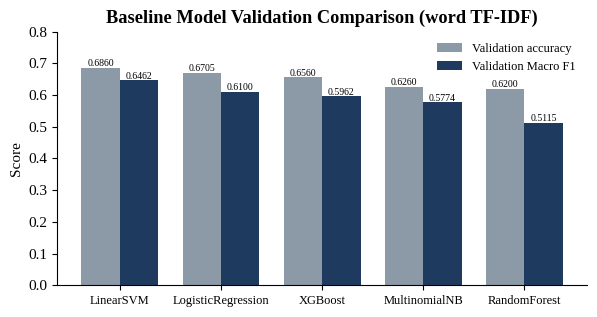

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_1_baseline_validation.png


In [5]:
# Figure 5.1 baseline validation
b = pd.read_csv(need(RES/'F02_baseline_validation.csv')).sort_values('Macro F1', ascending=False)
fig, ax = plt.subplots(figsize=(6.1, 3.3)); x = np.arange(len(b)); w = 0.38
for off, col, colr in ((-w/2, 'Accuracy', C['neu']), (w/2, 'Macro F1', C['navy'])):
    bars = ax.bar(x + off, b[col], w, color=colr, label=f'Validation {col.lower() if col=="Accuracy" else col}')
    for bb, v in zip(bars, b[col]): ax.text(bb.get_x() + bb.get_width() / 2, v + 0.005, f'{v:.4f}', ha='center', fontsize=7)
for _, r in b.iterrows(): log('5.1', r.Model, f"acc {r.Accuracy:.6f} / macroF1 {r['Macro F1']:.6f}")
ax.set_xticks(x); ax.set_xticklabels(b.Model, fontsize=9); ax.set_ylim(0, 0.8); ax.set_ylabel('Score'); ax.legend(frameon=False, fontsize=9)
ax.set_title('Baseline Model Validation Comparison (word TF-IDF)', fontweight='bold'); save(fig, 'Fig5_1_baseline_validation.png')

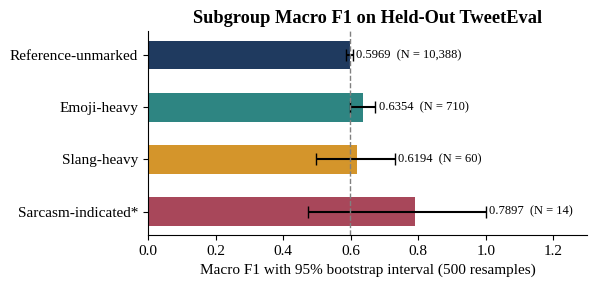

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_2_subgroup_macro_f1.png


In [6]:
# Figure 5.2 subgroup Macro F1 with bootstrap intervals
p = pd.read_csv(need(RES/'F05_RQ1_subgroup_performance.csv')).set_index('Subgroup')
order = ['reference-unmarked', 'emoji-heavy', 'slang-heavy', 'sarcasm-indicated']; p = p.loc[order]
fig, ax = plt.subplots(figsize=(6.1, 3.0)); y = np.arange(len(p))[::-1]
ax.barh(y, p['Macro F1'], color=[C['navy'], C['pos'], C['orange'], C['neg']], height=0.55)
ax.errorbar(p['Macro F1'], y, xerr=[p['Macro F1'] - p['Macro F1 CI Low'], p['Macro F1 CI High'] - p['Macro F1']], fmt='none', ecolor='black', capsize=4)
for yy, (g, r) in zip(y, p.iterrows()):
    ax.text(r['Macro F1 CI High'] + 0.01, yy, f"{r['Macro F1']:.4f}  (N = {int(r.N):,})", va='center', fontsize=9)
    log('5.2', g, f"{r['Macro F1']:.6f} [{r['Macro F1 CI Low']:.6f}, {r['Macro F1 CI High']:.6f}] N={int(r.N)}")
ax.axvline(p.loc['reference-unmarked', 'Macro F1'], ls='--', color='gray', lw=1)
ax.set_yticks(y); ax.set_yticklabels([g.capitalize() + ('*' if g.startswith('sarc') else '') for g in order]); ax.set_xlim(0, 1.3)
ax.set_xlabel('Macro F1 with 95% bootstrap interval (500 resamples)'); ax.set_title('Subgroup Macro F1 on Held-Out TweetEval', fontweight='bold')
save(fig, 'Fig5_2_subgroup_macro_f1.png')

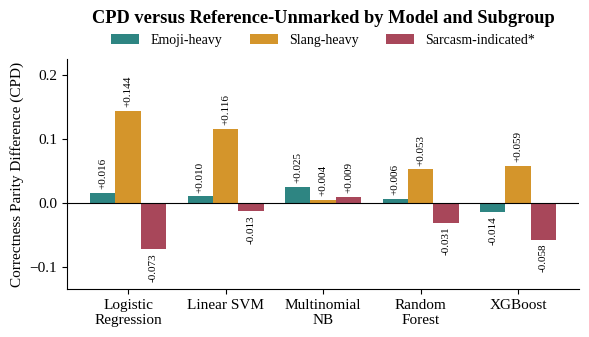

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_3_cpd.png


In [7]:
# Figure 5.3 CPD by model and subgroup (labels rounded once, from full-precision values)
c = pd.read_csv(need(RES/'F05_RQ2_CPD_CRR_five_models.csv'))
models = ['LogisticRegression', 'LinearSVM', 'MultinomialNB', 'RandomForest', 'XGBoost']
groups = [('emoji-heavy', 'Emoji-heavy', C['pos']), ('slang-heavy', 'Slang-heavy', C['orange']), ('sarcasm-indicated', 'Sarcasm-indicated*', C['neg'])]
fig, ax = plt.subplots(figsize=(6.1, 3.5)); x = np.arange(len(models)); w = 0.26
for i, (g, name, col) in enumerate(groups):
    v = [float(c[(c.Model == m) & (c.Subgroup == g)].CPD.iloc[0]) for m in models]
    bars = ax.bar(x + (i - 1) * w, v, w, color=col, label=name)
    for bb, val, m in zip(bars, v, models):
        ax.text(bb.get_x() + bb.get_width() / 2, val + (0.006 if val >= 0 else -0.006), f'{val:+.3f}', rotation=90, ha='center', va='bottom' if val >= 0 else 'top', fontsize=8)
        log('5.3', f'{m} {g}', round(val, 6))
ax.axhline(0, color='black', lw=0.8); ax.set_xticks(x)
ax.set_xticklabels(['Logistic\nRegression', 'Linear SVM', 'Multinomial\nNB', 'Random\nForest', 'XGBoost'])
ax.set_ylim(-0.135, 0.225); ax.set_ylabel('Correctness Parity Difference (CPD)')
ax.legend(ncol=3, frameon=False, loc='lower center', bbox_to_anchor=(0.5, 1.0), fontsize=10)
ax.set_title('CPD versus Reference-Unmarked by Model and Subgroup', fontweight='bold', pad=26); save(fig, 'Fig5_3_cpd.png')

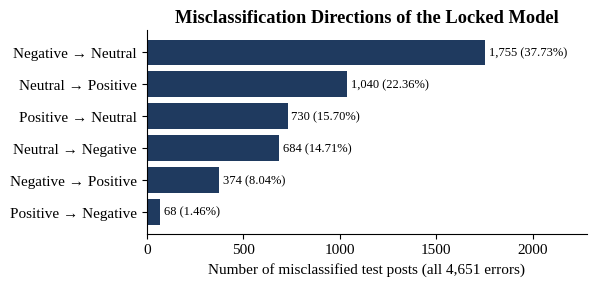

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_4_error_directions.png


In [8]:
# Figure 5.4 error directions
e = pd.read_csv(need(RES/'F06_all_error_directions.csv')).sort_values('N Errors')
fig, ax = plt.subplots(figsize=(6.1, 3.0))
ax.barh(e['Error Direction'].str.replace(' -> ', ' → ').str.title(), e['N Errors'], color=C['navy'])
for i, (_, r) in enumerate(e.iterrows()):
    ax.text(r['N Errors'] + 20, i, f"{int(r['N Errors']):,} ({r['% of All Errors']:.2f}%)", va='center', fontsize=9)
    log('5.4', r['Error Direction'], f"{int(r['N Errors'])} ({r['% of All Errors']:.4f}%)")
ax.set_xlim(0, e['N Errors'].max() * 1.3); ax.set_xlabel(f"Number of misclassified test posts (all {int(e['N Errors'].sum()):,} errors)")
ax.set_title('Misclassification Directions of the Locked Model', fontweight='bold'); save(fig, 'Fig5_4_error_directions.png')

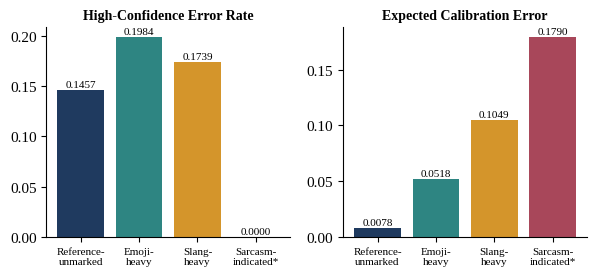

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_5_hcer_ece.png


In [9]:
# Figure 5.5 HCER and ECE by subgroup
cc = pd.read_csv(need(RES/'F07_confidence_calibration_by_subgroup.csv')).set_index('Subgroup').loc[['reference-unmarked', 'emoji-heavy', 'slang-heavy', 'sarcasm-indicated']]
fig, axs = plt.subplots(1, 2, figsize=(6.1, 2.9))
for ax, col, title in ((axs[0], 'HCER', 'High-Confidence Error Rate'), (axs[1], 'ECE', 'Expected Calibration Error')):
    bars = ax.bar(range(4), cc[col], color=[C['navy'], C['pos'], C['orange'], C['neg']])
    for bb, v in zip(bars, cc[col]): ax.text(bb.get_x() + bb.get_width() / 2, v + 0.003, f'{v:.4f}', ha='center', fontsize=8)
    for g, v in cc[col].items(): log('5.5', f'{col} {g}', round(float(v), 6))
    ax.set_xticks(range(4)); ax.set_xticklabels(['Reference-\nunmarked', 'Emoji-\nheavy', 'Slang-\nheavy', 'Sarcasm-\nindicated*'], fontsize=8)
    ax.set_title(title, fontweight='bold', fontsize=10)
save(fig, 'Fig5_5_hcer_ece.png')


SemEval-2014 columns: ['Model', 'Accuracy', 'Macro F1', 'Weighted F1', 'Macro Precision', 'Macro Recall', 'MCC', 'Cohen Kappa', 'Brier', 'Target Dataset', 'Condition', 'Evaluation Unit', 'Target N', 'Unique Sentences', 'TweetEval Source 3-Class N', 'TweetEval Source 3-Class Accuracy', 'TweetEval Source 3-Class Macro F1', 'Accuracy Delta vs TweetEval Source', 'Macro F1 Delta vs TweetEval Source']
Model                                    FinalSelectedPipeline
Accuracy                                              0.648464
Macro F1                                              0.573551
Weighted F1                                           0.662279
Macro Precision                                       0.610435
Macro Recall                                          0.576669
MCC                                                   0.403031
Cohen Kappa                                           0.392975
Brier                                                 0.149901
Target Dataset                   

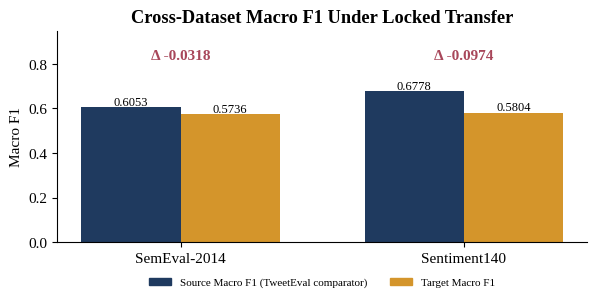

saved /content/drive/MyDrive/LJMU_FINAL_EXPERIMENT_RUN/figures/thesis_regenerated/Fig5_6_cross_dataset.png


In [11]:
# Figure 5.6 cross-dataset Macro F1 (robust column selection + self-check)
def find_col(df, *patterns, exclude=()):
    for c_ in df.columns:
        if all(re.search(p_, c_, re.I) for p_ in patterns) and not any(re.search(x, c_, re.I) for x in exclude):
            return c_
    return None

rows = []
for f, name in (('F10_SemEval_domain_task_shift.csv', 'SemEval-2014'),
                ('F09_Sentiment140_binary_robustness.csv', 'Sentiment140')):
    d = pd.read_csv(need(RES/f)); r = d.iloc[0]
    print(f'\n{name} columns:', list(d.columns)); print(r.to_string())
    tgt_col = (next((c_ for c_ in d.columns if c_.strip().lower() == 'macro f1'), None)
               or find_col(d, 'target', 'macro', 'f1')
               or find_col(d, 'macro', 'f1', exclude=('source', 'delta', 'weighted', 'ci', 'gap')))
    src_col = find_col(d, 'source', 'macro', 'f1') or find_col(d, 'comparator', 'macro')
    assert tgt_col and src_col, f'could not identify columns: target={tgt_col}, source={src_col}'
    tgt, src = float(r[tgt_col]), float(r[src_col])
    dcol = find_col(d, 'delta', 'macro')
    if dcol: assert abs((tgt - src) - float(r[dcol])) < 1e-9, f'delta check failed: {tgt - src} vs {r[dcol]}'
    print(f'-> using target="{tgt_col}" ({tgt:.6f}), source="{src_col}" ({src:.6f})' + (f', delta matches "{dcol}"' if dcol else ''))
    rows.append((name, src, tgt)); log('5.6', name, f'source {src:.6f} target {tgt:.6f} delta {tgt - src:+.6f}')

fig, ax = plt.subplots(figsize=(6.1, 3.2)); w = 0.35
for i, (name, s, t) in enumerate(rows):
    for off, v, col in ((-w/2, s, C['navy']), (w/2, t, C['orange'])):
        ax.bar(i + off, v, w, color=col); ax.text(i + off, v + 0.01, f'{v:.4f}', ha='center', fontsize=9)
    ax.text(i, 0.82, f'Δ {t - s:+.4f}', ha='center', color=C['neg'], fontweight='bold')
ax.set_xticks(range(len(rows))); ax.set_xticklabels([r[0] for r in rows]); ax.set_ylim(0, 0.95); ax.set_ylabel('Macro F1')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C['navy']), plt.Rectangle((0, 0), 1, 1, color=C['orange'])],
          labels=['Source Macro F1 (TweetEval comparator)', 'Target Macro F1'], frameon=False, fontsize=8,
          loc='upper center', bbox_to_anchor=(0.5, -0.12), ncol=2)
ax.set_title('Cross-Dataset Macro F1 Under Locked Transfer', fontweight='bold'); save(fig, 'Fig5_6_cross_dataset.png')

In [12]:
pd.DataFrame(VALUES).to_csv(OUT/'FIGURE_VALUES.csv', index=False)
print(pd.DataFrame(VALUES).to_string()); print('\nAll figures and FIGURE_VALUES.csv saved to', OUT)

   figure                                  item                                            value
0     3.6                        train Negative                                    7093 (15.55%)
1     3.6                   validation Negative                                     312 (15.60%)
2     3.6                         test Negative                                    3972 (32.33%)
3     3.6                         train Neutral                                   20673 (45.32%)
4     3.6                    validation Neutral                                     869 (43.45%)
5     3.6                          test Neutral                                    5937 (48.33%)
6     3.6                        train Positive                                   17849 (39.13%)
7     3.6                   validation Positive                                     819 (40.95%)
8     3.6                         test Positive                                    2375 (19.33%)
9     3.7                     